# Week 17: Attention as a learned kernel on a wake

Which properties follow from the attention algebra, and which require physical validation?

**Prerequisites:** Weeks 7.3 and 15 introduced applications. Here we open the mechanism and audit it.

Allow 120 minutes for the guided lab; estimate 3–5 hours total with reading and written analysis. This planning estimate has not been measured in a student pilot. Student edition: worked examples run immediately; set RUN_EXERCISES=True after completing the four functions. Incomplete tasks are reported, never counted as passes.

## Laboratory route and reading map

| Notebook stage | What enters the calculation | What to inspect |
|---|---|---|
| Random Q/K/V demonstration | Sixteen v/U observations and their x/D,y/D coordinates; random fixed projections | Weight rows sum to one; record tensor shapes and the temperature effect |
| Geometry versus content kernels | The same coordinates and three flow frames | A changed sensor value changes content attention; moving a coordinate changes the physical input |
| Retained trained heads | Saved Sensor-set weights and saved normalization, clean Re110 frames | Head differences are conditional weights, not causal influence |
| Tasks 1–4 | Your stable softmax, permutation, temperature and masked-attention functions | Algebraic tests plus a controlled perturbation report |

Start with the default 16 sensors. Keep observations, coordinates, projection seed and head width fixed when changing temperature. The source POD basis used to place sensors is fitted on Re90 frames 0–159. The displayed Re110 frame is an already inspected mechanism example, not a new held-out accuracy claim. A dot on the wake plot is an observation location; the rectangular ROI boundary is not a wall.

In [1]:
from pathlib import Path
import sys, os, subprocess, importlib.util
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'flowmllab/transformer_course.py').exists()), None)
try:
    _in_colab = importlib.util.find_spec("google.colab") is not None
except (ModuleNotFoundError, ValueError):
    _in_colab = False
if _in_colab:
    _course_target = ROOT if ROOT is not None else Path("/content/FlowMLLab")
    if not _course_target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--sparse", "https://github.com/Ehsan-Roohi/FlowMLLab.git",
                        str(_course_target)], check=True)
    _course_complete = all((_course_target / p).exists() for p in ['flowmllab/transformer_course.py', 'flowmllab', 'course/lessons', 'data/modal_labs', 'results/transformer_course_v3', 'results/transformer_sensor_ablation', 'notebooks/week07_3', 'notebooks/week07_4', 'docs', 'flowmllab/late_teaching_plots.py'])
    if not _course_complete and (_course_target / ".git").exists():
        _sparse = subprocess.run(["git", "-C", str(_course_target), "config", "--bool",
                                  "core.sparseCheckout"], capture_output=True, text=True, check=False)
        if _sparse.stdout.strip() != "true":
            raise RuntimeError("This full checkout is missing required lesson files; use a complete course checkout or a new Colab runtime.")
        # Add this lesson's dependencies; keep any previous sparse selection.
        subprocess.run(["git", "-C", str(_course_target), "sparse-checkout",
                        "add", *['flowmllab', 'course/lessons', 'data/modal_labs', 'results/transformer_course_v3', 'results/transformer_sensor_ablation', 'notebooks/week07_3', 'notebooks/week07_4', 'docs']], check=True)
    elif not _course_complete:
        raise RuntimeError("The extracted course folder is incomplete for this lesson. Use the complete portable bundle or a new Colab runtime.")
    ROOT = _course_target
if ROOT is None or not all((ROOT / p).exists() for p in ['flowmllab/transformer_course.py', 'flowmllab', 'course/lessons', 'data/modal_labs', 'results/transformer_course_v3', 'results/transformer_sensor_ablation', 'notebooks/week07_3', 'notebooks/week07_4', 'docs', 'flowmllab/late_teaching_plots.py']):
    raise RuntimeError("Open this notebook in a FlowMLLab checkout, or use its Open in Colab link and run this setup cell first.")
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Course checkout:", ROOT)

import tempfile, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from flowmllab import transformer_course as lab
lab.seed_all(17)
cases,input_manifest=lab.load_data(ROOT)
EVIDENCE=ROOT/"results/transformer_course_v3"
_student_parent=ROOT/"student_runs/transformer_labs"
_student_parent.mkdir(parents=True,exist_ok=True)
workspace=tempfile.TemporaryDirectory(prefix="classroom-",dir=_student_parent)
RUN_OUTPUT=Path(workspace.name)
task_status={}
print("Loaded checksummed native wake fields. Optional student work stays in:",RUN_OUTPUT)

task_status={i:None for i in range(1,5)}


Course checkout: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo


Loaded checksummed native wake fields. Optional student work stays in: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo/student_runs/transformer_labs/classroom-unc6zwaz


In [2]:
RUN_EXERCISES=False

## Build Q, K and V from actual CFD sensors

Coordinates are geometric features, not a sequence order. Use the first retained Re110 snapshot only as a worked example; these random weights are not a learned physical law.

X, Q, attention, output: torch.Size([3, 16, 3]) torch.Size([3, 16, 8]) torch.Size([3, 16, 16]) torch.Size([3, 16, 8])


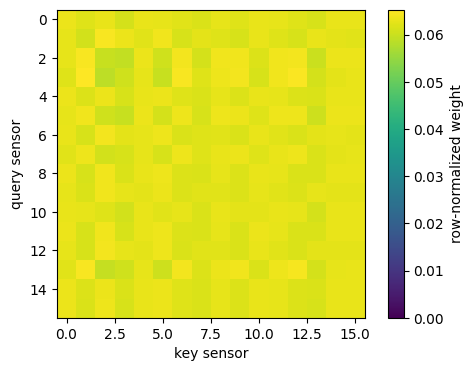

In [3]:
rep=lab.Representation.fit(cases[90]['v'][:160],8)
ids=lab.qr_sensors(rep,16)
tokens=lab.sensor_tokens(cases[110]['v'][100:103],ids,cases[90],0.,1.)
X=torch.tensor(tokens,dtype=torch.float32)
Wq,Wk,Wv=[torch.randn(3,8)/np.sqrt(3) for _ in range(3)]
Q,K,V=X@Wq,X@Wk,X@Wv
A,weights=lab.attention(Q,K,V)
print('X, Q, attention, output:',X.shape,Q.shape,weights.shape,A.shape)
assert torch.allclose(weights.sum(-1),torch.ones(3,16))
plt.figure(figsize=(6,4));plt.imshow(weights[0].numpy(),vmin=0,cmap='viridis');plt.colorbar(label='row-normalized weight');plt.xlabel('key sensor');plt.ylabel('query sensor');plt.show()

## Separate a kernel picture from a trained interpretation

A spatial-distance kernel supplies a geometry-only comparator. Neither picture is evidence of causal influence. Change a sensor value and recompute both kernels.

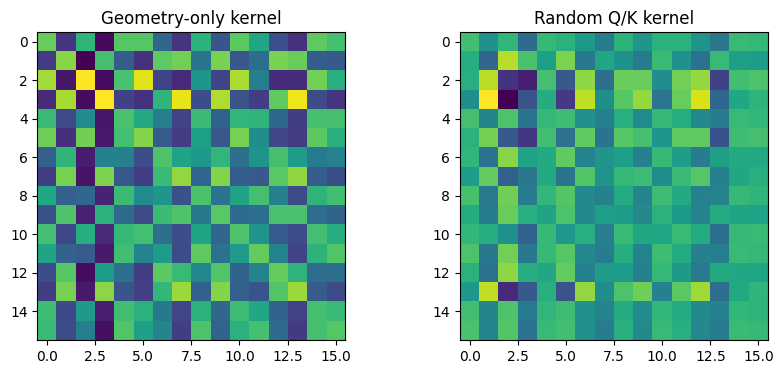

In [4]:
xy=tokens[0,:,1:]
distance=((xy[:,None]-xy[None,:])**2).sum(-1)
geometry=np.exp(-distance/.1);geometry/=geometry.sum(1,keepdims=True)
order=torch.randperm(16)
permuted,_=lab.attention(Q[:,order],K[:,order],V[:,order])
torch.testing.assert_close(permuted,A[:,order])
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(geometry);axes[0].set_title('Geometry-only kernel')
axes[1].imshow(weights[0].numpy());axes[1].set_title('Random Q/K kernel')
plt.show()

## Inspect the retained trained heads

Read-only inspection of Sensor-set seed 17, Re=110 frames 80, 120, 160. Full width is 24, four heads have width 6; the softmax scale uses head width. Values use the saved training mean/scale. These clean-input attention maps differ from the noisy evaluation experiment and are not causal explanations. The earlier random projection demonstration is a separate mechanism example.

{'checkpoint_sha256': '418b39049f4c10e54b9f459c9d62f90d6d4d9e13aad1a2c2ab5d9522d249704c', 'case_Re': 110, 'seed': 17, 'frames': [80, 120, 160], 'full_width': 24, 'head_width': 6}


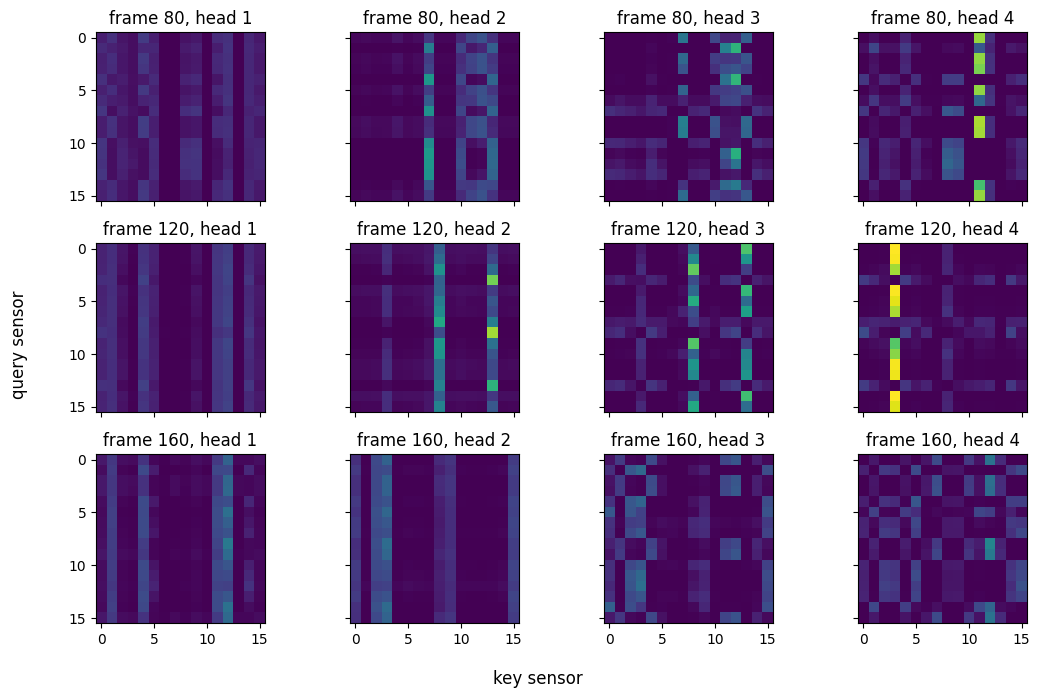

In [5]:
states=torch.load(EVIDENCE/'checkpoints.pt',map_location='cpu',weights_only=True)
bundle=states['sensors__Sensor-set-17'];trained_sensor,trained_rep=lab.checkpoint_model(bundle)
frames=[80,120,160]
trained_tokens=lab.sensor_tokens(cases[110]['v'][frames],bundle['sensor_ids'].numpy(),cases[90],bundle['value_mean'],bundle['value_scale'])
with torch.no_grad():
    embedded=trained_sensor.embed(torch.tensor(trained_tokens,dtype=torch.float32))
    b,n,width=embedded.shape;heads=trained_sensor.block.heads
    q,k,v=trained_sensor.block.qkv(trained_sensor.block.norm(embedded)).reshape(b,n,3,heads,width//heads).permute(2,0,3,1,4).unbind(0)
    _,trained_weights=lab.attention(q,k,v)
    torch.testing.assert_close(trained_weights.sum(-1),torch.ones(b,heads,n))
print({'checkpoint_sha256':lab.digest(EVIDENCE/'checkpoints.pt'),'case_Re':110,'seed':17,'frames':frames,'full_width':width,'head_width':width//heads})
fig,axes=plt.subplots(3,heads,figsize=(11,7),sharex=True,sharey=True)
for i,frame in enumerate(frames):
    for head in range(heads):
        axes[i,head].imshow(trained_weights[i,head].numpy(),vmin=0,vmax=float(trained_weights.max()),cmap='viridis')
        axes[i,head].set_title(f'frame {frame}, head {head+1}')
fig.supxlabel('key sensor');fig.supylabel('query sensor');fig.tight_layout();plt.show()

## Locate the observations in the actual wake

The field is native LBM v/U, Re110, frame100. Overlay the exact frozen sensor locations; sensor indices in the heatmaps refer to these physical points.

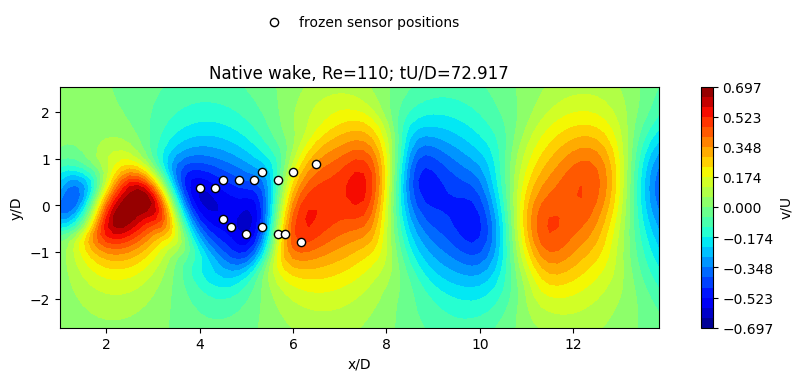

In [6]:
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
case=cases[110];frame=100
field=case["v"][frame];bound=float(np.max(np.abs(field)))
im=ax.contourf(case["x"],case["y"],field,levels=np.linspace(-bound,bound,25),cmap="jet")
yy,xx=np.meshgrid(case["y"],case["x"],indexing="ij")
ax.scatter(xx.ravel()[ids],yy.ravel()[ids],facecolor="white",edgecolor="black",s=35,label="frozen sensor positions")
ax.set(xlabel="x/D",ylabel="y/D",aspect="equal",title=f"Native wake, Re=110; tU/D={case['t'][frame]:.3f}")
ax.legend(loc="upper center",bbox_to_anchor=(.5,1.35),frameon=False)
fig.colorbar(im,ax=ax,label="v/U")
plt.show()


## Task 1: Scaled attention

Implement row-stable scaled dot-product attention without calling lab.attention. Explain the square-root scaling.

Interface contract: Inputs are floating Torch tensors q,k:[...,N,d], v:[...,N,d_v] with identical optional batch axes and matching N (2-D or 3-D). Return a [...,N,d_v] tensor; normalize over keys.

In [7]:
def student_attention(q,k,v):
    """Inputs are floating Torch tensors q,k:[...,N,d], v:[...,N,d_v] with identical optional batch axes and matching N (2-D or 3-D). Return a [...,N,d_v] tensor; normalize over keys."""
    raise NotImplementedError

In [8]:
if RUN_EXERCISES:
    try:
        g=torch.Generator().manual_seed(1701)
        for shape in [(5,3),(2,5,3),(1,9,6)]:
            q,k=[torch.randn(*shape,generator=g) for _ in range(2)]
            v=torch.randn(*shape[:-1],4,generator=g)
            expected=(q@k.transpose(-2,-1)/np.sqrt(shape[-1])).softmax(-1)@v
            result=student_attention(q,k,v)
            assert result.shape==(*shape[:-1],4)
            torch.testing.assert_close(result,expected)
            torch.testing.assert_close(student_attention(q,k,2*v),2*expected)
        task_status[1]=True
    except NotImplementedError:
        task_status[1]=None
    except Exception as exc:
        task_status[1]=False
        print("Task 1 check failed:",type(exc).__name__,str(exc))
else:
    task_status[1]=None
print("Task 1:","PASS" if task_status[1] is True else "NOT SUBMITTED" if task_status[1] is None else "FAILED")

Task 1: NOT SUBMITTED


## Task 2: Permutation experiment

Write a function returning the largest equivariance error after consistently permuting all sensor tokens.

Interface contract: Inputs q,k:[N,d], v:[N,d_v] are the unbatched (2-D) Task 1 shapes. order is a length-N Torch permutation. attention_fn is an explicit callable returning the attended tensor, not a weights/output tuple. Return a Python float: maximum absolute equivariance discrepancy. Do not consult a global attention function.

In [9]:
def permutation_error(q,k,v,order,attention_fn):
    """Inputs q,k:[N,d], v:[N,d_v] are the unbatched (2-D) Task 1 shapes. order is a length-N Torch permutation. attention_fn is an explicit callable returning the attended tensor, not a weights/output tuple. Return a Python float: maximum absolute equivariance discrepancy. Do not consult a global attention function."""
    raise NotImplementedError

In [10]:
if RUN_EXERCISES:
    try:
        for n,d in ((5,3),(9,2)):
            q=torch.randn(n,d);k=torch.randn(n,d);v=torch.randn(n,4);order=torch.randperm(n)
            assert permutation_error(q,k,v,order,student_attention)<1e-5
        def order_biased_attention(q,k,v):
            return torch.arange(q.shape[0],dtype=q.dtype)[:,None].expand(q.shape[0],v.shape[-1])
        q=torch.randn(5,3);k=torch.randn(5,3);v=torch.randn(5,2);order=torch.arange(4,-1,-1)
        assert permutation_error(q,k,v,order,order_biased_attention)>1
        task_status[2]=True
    except NotImplementedError:
        task_status[2]=None
    except Exception as exc:
        task_status[2]=False
        print("Task 2 check failed:",type(exc).__name__,str(exc))
else:
    task_status[2]=None
print("Task 2:","PASS" if task_status[2] is True else "NOT SUBMITTED" if task_status[2] is None else "FAILED")

Task 2: NOT SUBMITTED


## Task 3: Temperature limit

Implement temperature-scaled weights; verify that large temperature moves them toward uniform weights.

Interface contract: Return a [...,N,N] Torch tensor for q,k:[...,N,d] with identical optional batch axes (2-D or 3-D). Divide scaled scores by the finite temperature; nonfinite or nonpositive temperature must raise ValueError.

In [11]:
def temperature_weights(q,k,temperature):
    """Return a [...,N,N] Torch tensor for q,k:[...,N,d] with identical optional batch axes (2-D or 3-D). Divide scaled scores by the finite temperature; nonfinite or nonpositive temperature must raise ValueError."""
    raise NotImplementedError

In [12]:
if RUN_EXERCISES:
    try:
        for shape in [(5,3),(2,7,4)]:
            q,k=[torch.randn(*shape) for _ in range(2)]
            for temperature in (.3,2.5,1e6):
                expected=(q@k.transpose(-2,-1)/np.sqrt(shape[-1])/temperature).softmax(-1)
                torch.testing.assert_close(temperature_weights(q,k,temperature),expected)
            torch.testing.assert_close(temperature_weights(q,k,1e6),torch.full((*shape[:-1],shape[-2]),1/shape[-2]),atol=1e-5,rtol=1e-5)
        for temperature in (0.,-1.,float('nan'),float('inf')):
            try:
                temperature_weights(q,k,temperature)
                raise AssertionError('invalid temperature accepted')
            except ValueError:pass
        task_status[3]=True
    except NotImplementedError:
        task_status[3]=None
    except Exception as exc:
        task_status[3]=False
        print("Task 3 check failed:",type(exc).__name__,str(exc))
else:
    task_status[3]=None
print("Task 3:","PASS" if task_status[3] is True else "NOT SUBMITTED" if task_status[3] is None else "FAILED")

Task 3: NOT SUBMITTED


## Task 4: Build an attention investigation

Implement attention over several temperatures and optional key masks. Return weights, output and mean entropy for each temperature. Reject a mask with an empty row. Then vary the temperature and remove half the keys; plot entropy and output change, explaining why constant values hide changes in attention.

Interface contract: Inputs q:[Nq,d], k:[Nk,d], v:[Nk,d_v] are 2-D floating Torch tensors. temperatures is a nonempty sequence of positive scalars. mask is None or a Boolean tensor broadcastable to [Nq,Nk]: True ALLOWS a key (the opposite of torch MultiheadAttention blocking-mask semantics). Invalid tensor dimensions, mismatched widths/counts, nonpositive temperature or a query with no allowed key must raise ValueError. Return a list in temperature order of dictionaries with keys temperature (float), weights ([Nq,Nk] tensor), output ([Nq,d_v] tensor), entropy (float, mean over queries of natural-log entropy).

In [13]:
def attention_investigation(q,k,v,temperatures,mask=None):
    """Inputs q:[Nq,d], k:[Nk,d], v:[Nk,d_v] are 2-D floating Torch tensors. temperatures is a nonempty sequence of positive scalars. mask is None or a Boolean tensor broadcastable to [Nq,Nk]: True ALLOWS a key (the opposite of torch MultiheadAttention blocking-mask semantics). Invalid tensor dimensions, mismatched widths/counts, nonpositive temperature or a query with no allowed key must raise ValueError. Return a list in temperature order of dictionaries with keys temperature (float), weights ([Nq,Nk] tensor), output ([Nq,d_v] tensor), entropy (float, mean over queries of natural-log entropy)."""
    raise NotImplementedError

In [14]:
if RUN_EXERCISES:
    try:
        g=torch.Generator().manual_seed(1704)
        q,k,v=[torch.randn(5,3,generator=g) for _ in range(3)]
        mask=torch.ones(5,5,dtype=torch.bool);mask[:,-2:]=False
        for use_mask in (None,mask):
            result=attention_investigation(q,k,v,[.5,3.],use_mask)
            assert len(result)==2
            for r in result:
                scores=q@k.transpose(-2,-1)/np.sqrt(3)/r['temperature']
                if use_mask is not None:scores=scores.masked_fill(~use_mask,float('-inf'))
                expected=scores.softmax(-1)
                torch.testing.assert_close(r['weights'],expected)
                torch.testing.assert_close(r['output'],expected@v)
                assert np.isclose(r['entropy'],float(-(expected*expected.clamp_min(1e-30).log()).sum(-1).mean()))
            assert result[0]['entropy']<result[1]['entropy']
        try:
            attention_investigation(q,k,v,[1.],torch.zeros(5,5,dtype=torch.bool))
            raise AssertionError('empty mask accepted')
        except ValueError:pass
        for temp in (0.,-1.):
            try:
                attention_investigation(q,k,v,[temp])
                raise AssertionError("nonpositive temperature accepted")
            except ValueError:pass
        task_status[4]=True
    except NotImplementedError:
        task_status[4]=None
    except Exception as exc:
        task_status[4]=False
        print("Task 4 check failed:",type(exc).__name__,str(exc))
else:
    task_status[4]=None
print("Task 4:","PASS" if task_status[4] is True else "NOT SUBMITTED" if task_status[4] is None else "FAILED")

Task 4: NOT SUBMITTED


## Assessment: 100 points

Coding Tasks 1–4: [5, 5, 5, 25] points; derivation 25, interpretation 25, reproducibility 10. Automated checks assess only coding behavior.

Derive: derive row normalization and square-root scaling.

Worked interpretation: Attention weights depend on content but do not identify causal influence. Equal values make output invariant even when weights change.

Reject and explain: “The bright head proves this sensor causes shedding.”

An accurate numerical observation without its split, representation, or causal limitation earns at most half of interpretation points. Instructor marking and a timed student pilot are still required; automated checks establish interface/behavior only.



## Interpretation and submission

Submit the four completed functions, the requested plots/tables, and a 300-word claim ledger. Distinguish observations, fitted quantities, independent evaluation and unsupported extrapolation. Retain failed seeds. Use the lecture source for the rubric and assumptions.

In [15]:
print("Coding tasks passed:",sum(v is True for v in task_status.values()),"/",len(task_status))
workspace.cleanup()

Coding tasks passed: 0 / 4
